# Lab 2: Data Cleaning and Preprocessing

**Course:** IT7103 Advanced AI Applications
**Lecture:** Data Cleaning and Preprocessing  
**Tools:** Python, NumPy, Pandas, Matplotlib, Seaborn, and scikit-learn preprocessing tools  
**Dataset:** Wine Recognition dataset from scikit-learn

This notebook is a guided practical lab. You will run code, inspect outputs, and write short explanations.  
At the end, there is a final mini-project that you should complete independently in a separate notebook.

The lecture used the Titanic dataset as the main example. This lab uses a different dataset so that students can transfer the same preprocessing ideas to a new context.

## 1. Setup

Run this cell first. The libraries are grouped according to their roles.

`numpy` is used for numerical operations.  
`pandas` is used for working with tabular data.  
`matplotlib` and `seaborn` are used for visualization.  
`scikit-learn` provides the dataset and preprocessing tools.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

%matplotlib inline

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Part A - Load the real dataset

The Wine Recognition dataset is a real classification dataset. Each row represents one wine sample.  
The numerical features describe chemical measurements of the wine, and the target column represents the wine class.

In a real data-science or AI workflow, we should always begin by loading the data and understanding what each row and column means before cleaning or transforming anything.

In [ ]:
wine = load_wine(as_frame=True)

df_raw = wine.frame.copy()
df_raw = df_raw.rename(columns={"target": "wine_class"})

# Add readable class names.
class_name_map = {i: name for i, name in enumerate(wine.target_names)}
df_raw["wine_class_name"] = df_raw["wine_class"].map(class_name_map)

df_raw.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,wine_class,wine_class_name
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0


**Explanation:**  
The dataset is now stored in `df_raw`. The name `raw` is important because it reminds us not to overwrite the original version.  
The column `wine_class` is the target label, while the other chemical measurements are input features.  
The column `wine_class_name` is added only to make the target easier to read.

## 3. Part B - Initial inspection

Initial inspection helps us answer basic questions before cleaning:

What is the shape of the dataset?  
What are the column names?  
Which columns are numerical or categorical?  
Are there missing values?  
Are there duplicate rows?  
What are the basic descriptive statistics?

In [ ]:
print("Shape of raw dataset:", df_raw.shape)

print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nData types:")
print(df_raw.dtypes)

print("\nMissing values:")
print(df_raw.isna().sum())

print("\nDuplicate rows:")
print(df_raw.duplicated().sum())

Shape of raw dataset: (178, 15)

Column names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'wine_class', 'wine_class_name']

Data types:
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
wine_class                        int64
wine_class_name                  object
dtype: object

Missing values:
alcohol                         0
malic_acid                      

In [ ]:
df_raw.describe(include="all")

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,wine_class,wine_class_name
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,class_1
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,71
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202,NaN
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035,NaN
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000,NaN
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000,NaN
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000,NaN
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000,NaN


**Interpretation question B1:**  
Write one short sentence explaining what one row represents in this dataset.

**Interpretation question B2:**  
Identify the target column and at least three numerical feature columns.

## 4. Part C - Create a controlled dirty dataset for practice

The original Wine dataset is already clean, so it is not ideal for practicing data cleaning directly.  
Therefore, this lab creates a controlled dirty teaching copy. This is common in teaching because it allows students to practice realistic problems while still using a real dataset.

The dirty copy will include:

Missing values.  
Duplicate records.  
Invalid negative values in positive-only columns.  
Inconsistent category labels.  
Suspicious outliers.

The goal is not to damage the dataset randomly. The goal is to create a reproducible practice scenario.

In [ ]:
def make_dirty_wine_dataset(clean_df, random_state=42):
    """
    Create a controlled dirty version of the Wine dataset for teaching data cleaning.

    The original Wine dataset is already clean and numerical.
    For this lab, we deliberately add common real-world data problems:
    missing values, duplicates, invalid negative values, inconsistent categories,
    and suspicious outliers.

    Parameters
    ----------
    clean_df : pandas.DataFrame
        The clean Wine dataset.
    random_state : int
        Random seed used to make the dirty dataset reproducible.

    Returns
    -------
    pandas.DataFrame
        A dirty teaching copy of the dataset.
    """
    rng = np.random.default_rng(random_state)
    df_dirty = clean_df.copy()

    # Add a simple identifier column.
    # This is useful for auditing records but should not be treated as a predictive feature.
    df_dirty.insert(0, "sample_id", np.arange(1, len(df_dirty) + 1))

    # Create a categorical teaching feature from the numerical alcohol column.
    # This gives students a realistic chance to practice categorical cleaning and encoding.
    df_dirty["alcohol_level"] = pd.cut(
        df_dirty["alcohol"],
        bins=[0, 12.5, 13.5, np.inf],
        labels=["low", "medium", "high"]
    ).astype("object")

    # Introduce inconsistent category formatting.
    df_dirty.loc[0, "alcohol_level"] = "High "
    df_dirty.loc[1, "alcohol_level"] = "high"
    df_dirty.loc[2, "alcohol_level"] = "MEDIUM"
    df_dirty.loc[3, "alcohol_level"] = " medium "
    df_dirty.loc[4, "alcohol_level"] = "Low"
    df_dirty.loc[5, "alcohol_level"] = "unknown"

    # Introduce missing values in several numerical columns.
    missing_plan = {
        "alcohol": 8,
        "malic_acid": 10,
        "flavanoids": 9,
        "proline": 7
    }

    for column, n_missing in missing_plan.items():
        missing_rows = rng.choice(df_dirty.index, size=n_missing, replace=False)
        df_dirty.loc[missing_rows, column] = np.nan

    # Introduce missing values in the categorical teaching column.
    cat_missing_rows = rng.choice(df_dirty.index, size=5, replace=False)
    df_dirty.loc[cat_missing_rows, "alcohol_level"] = np.nan

    # Introduce invalid negative values in columns that should be positive.
    df_dirty.loc[8, "alcohol"] = -13.0
    df_dirty.loc[12, "proline"] = -999.0

    # Introduce suspicious but not automatically impossible outliers.
    df_dirty.loc[20, "proline"] = 5000.0
    df_dirty.loc[25, "color_intensity"] = 25.0

    # Add two duplicate records.
    duplicate_rows = df_dirty.iloc[[10, 30]].copy()
    df_dirty = pd.concat([df_dirty, duplicate_rows], ignore_index=True)

    return df_dirty

In [ ]:
df_dirty = make_dirty_wine_dataset(df_raw)

print("Raw dataset shape:", df_raw.shape)
print("Dirty dataset shape:", df_dirty.shape)

df_dirty.head(10)

Raw dataset shape: (178, 15)
Dirty dataset shape: (180, 17)


,sample_id,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,wine_class,wine_class_name,alcohol_level
0,1,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0,High
1,2,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0,high
2,3,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0,MEDIUM
3,4,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0,medium
4,5,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0,Low
5,6,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0,0,class_0,unknown
6,7,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0,0,class_0,high
7,8,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,NaN,0,class_0,high
8,9,-13.00,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0,0,class_0,high
9,10,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0,0,class_0,high


**Explanation:**  
The dirty dataset has more rows than the raw dataset because duplicate records were added.  
It also contains a new identifier column called `sample_id` and a categorical teaching column called `alcohol_level`.  
These extra columns help us practice identifier handling and categorical preprocessing.

## 5. Part D - Diagnose data-quality problems

Data cleaning should start with diagnosis, not immediate editing.  
We first check missingness, duplicates, category values, and suspicious numerical ranges.

In [ ]:
missing_summary = pd.DataFrame({
    "missing_count": df_dirty.isna().sum(),
    "missing_percent": df_dirty.isna().mean() * 100
}).sort_values("missing_count", ascending=False)

missing_summary

,missing_count,missing_percent
malic_acid,10,5.555556
flavanoids,10,5.555556
alcohol,8,4.444444
proline,7,3.888889
alcohol_level,5,2.777778
sample_id,0,0.000000
magnesium,0,0.000000
alcalinity_of_ash,0,0.000000
ash,0,0.000000
nonflavanoid_phenols,0,0.000000


In [ ]:
print("Number of duplicated rows:", df_dirty.duplicated().sum())

print("\nUnique values in alcohol_level:")
print(df_dirty["alcohol_level"].unique())

print("\nRows with invalid negative alcohol:")
display(df_dirty[df_dirty["alcohol"] < 0])

print("\nRows with invalid negative proline:")
display(df_dirty[df_dirty["proline"] < 0])

Number of duplicated rows: 2

Unique values in alcohol_level:
['High ' 'high' 'MEDIUM' ' medium ' 'Low' 'unknown' nan 'medium' 'low']

Rows with invalid negative alcohol:


,sample_id,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,wine_class,wine_class_name,alcohol_level
8,9,-13.0,1.64,2.17,14.0,97.0,2.8,2.98,0.29,1.98,5.2,1.08,2.85,1045.0,0,class_0,high



Rows with invalid negative proline:


,sample_id,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,wine_class,wine_class_name,alcohol_level
12,13,13.75,1.73,2.41,16.0,89.0,2.6,2.76,0.29,1.81,5.6,1.15,2.9,-999.0,0,class_0,high


**Explanation:**  
Missing values show incompleteness.  
Duplicates may inflate the dataset and bias summaries.  
Inconsistent category labels such as `High `, `high`, and `MEDIUM` create artificial categories.  
Negative values in `alcohol` or `proline` are invalid because these chemical measurements should be positive.

**Task D1:**  
Write two data-quality problems that you can see from the output above.

**Task D2:**  
Explain why we should not immediately delete every unusual value.

## 6. Part E - Visualize missing values and suspicious values

Visualization makes data-quality problems easier to understand.  
A missing-value bar chart helps us see which columns need treatment.  
A boxplot helps us inspect extreme values.

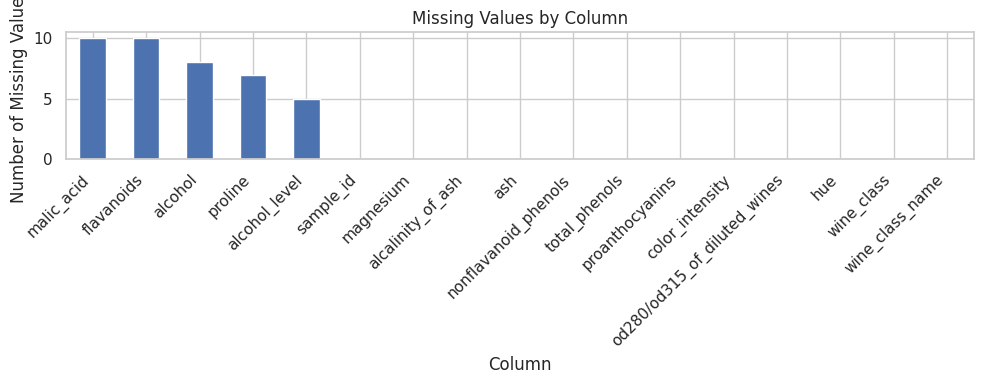

In [ ]:
plt.figure(figsize=(10, 4))
missing_summary["missing_count"].plot(kind="bar")
plt.title("Missing Values by Column")
plt.ylabel("Number of Missing Values")
plt.xlabel("Column")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

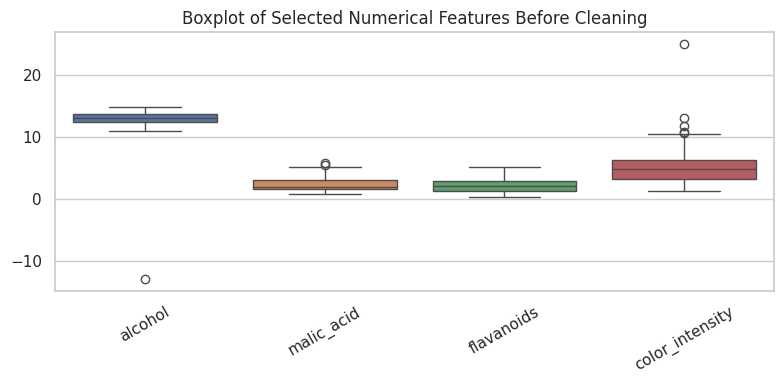

In [ ]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df_dirty[["alcohol", "malic_acid", "flavanoids", "color_intensity"]])
plt.title("Boxplot of Selected Numerical Features Before Cleaning")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Explanation:**  
The bar chart focuses on missing data. The boxplot focuses on numerical spread and unusual values.  
A boxplot can reveal suspicious observations, but it cannot tell us by itself whether a value is wrong. Domain knowledge is still needed.

## 7. Part F - Preserve the raw data and create a working copy

A professional preprocessing workflow keeps the original data unchanged.  
We clean a copy and record each decision.

In [ ]:
df_clean = df_dirty.copy()

cleaning_log = []

def add_log(step, reason):
    cleaning_log.append({"step": step, "reason": reason})

print("Working copy created.")

Working copy created.


## 8. Part G - Handle duplicate records

Duplicate records can lead to repeated observations.  
Before removing them, we check how many exist. Then we drop exact duplicate rows.

In [ ]:
print("Duplicates before cleaning:", df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates().reset_index(drop=True)
add_log("Removed exact duplicate rows", "Exact duplicates can inflate sample size and bias summaries.")

print("Duplicates after cleaning:", df_clean.duplicated().sum())
print("New shape:", df_clean.shape)

Duplicates before cleaning: 2
Duplicates after cleaning: 0
New shape: (178, 17)


**Task G1:**  
Why do we use `reset_index(drop=True)` after removing duplicates?

## 9. Part H - Treat invalid values

Some variables should not contain negative values.  
For this dataset, `alcohol` and `proline` should be positive measurements.  
If a value is invalid, a safe beginner strategy is to mark it as missing and then impute it later.

In [ ]:
positive_columns = ["alcohol", "malic_acid", "flavanoids", "proline", "color_intensity"]

for column in positive_columns:
    invalid_mask = df_clean[column] < 0
    invalid_count = invalid_mask.sum()

    if invalid_count > 0:
        df_clean.loc[invalid_mask, column] = np.nan
        add_log(
            f"Converted invalid negative values in {column} to NaN",
            "Negative values are not plausible for this positive chemical measurement."
        )

    print(f"{column}: invalid negative values found = {invalid_count}")

alcohol: invalid negative values found = 1
malic_acid: invalid negative values found = 0
flavanoids: invalid negative values found = 0
proline: invalid negative values found = 1
color_intensity: invalid negative values found = 0


In [ ]:
print("Missing values after converting invalid negatives to NaN:")
print(df_clean[positive_columns].isna().sum())

Missing values after converting invalid negatives to NaN:
alcohol             9
malic_acid         10
flavanoids          9
proline             8
color_intensity     0
dtype: int64


**Explanation:**  
Converting invalid values to `NaN` is often safer than inventing a corrected value.  
The imputation step will later replace these missing values using a consistent rule.

## 10. Part I - Clean inconsistent categorical labels

The column `alcohol_level` contains inconsistent category labels.  
We standardize the labels by removing extra spaces and converting text to lowercase.

In [ ]:
print("Before cleaning:")
print(df_clean["alcohol_level"].unique())

df_clean["alcohol_level"] = (
    df_clean["alcohol_level"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Treat the word "unknown" as missing because it does not represent a valid alcohol level.
df_clean["alcohol_level"] = df_clean["alcohol_level"].replace("unknown", pd.NA)

add_log(
    "Standardized alcohol_level categories",
    "Whitespace and capitalization differences should not create artificial categories."
)

print("\nAfter cleaning:")
print(df_clean["alcohol_level"].unique())

Before cleaning:
['High ' 'high' 'MEDIUM' ' medium ' 'Low' 'unknown' nan 'medium' 'low']

After cleaning:
<StringArray>
['high', 'medium', 'low', <NA>]
Length: 4, dtype: string


**Task I1:**  
Explain why category cleaning should happen before one-hot encoding.

## 11. Part J - Handle missing values

Missing-value treatment depends on the variable type.

Numerical columns: median imputation is a good beginner baseline because it is less affected by outliers than the mean.  
Categorical columns: mode imputation uses the most frequent category.  
Missing indicators: sometimes the fact that a value was missing may carry useful information.

In [ ]:
numerical_for_imputation = [
    "alcohol", "malic_acid", "flavanoids", "proline", "color_intensity"
]

# Create missing indicators before imputation.
for column in ["alcohol", "proline", "alcohol_level"]:
    df_clean[f"{column}_missing"] = df_clean[column].isna().astype(int)

add_log(
    "Created missing indicators",
    "Missingness itself may be informative and should be preserved before imputation."
)

print(df_clean[[col for col in df_clean.columns if col.endswith("_missing")]].head())

   alcohol_missing  proline_missing  alcohol_level_missing
0                0                0                      0
1                0                0                      0
2                0                0                      0
3                0                0                      0
4                0                0                      0


In [ ]:
# Median imputation for selected numerical columns.
for column in numerical_for_imputation:
    median_value = df_clean[column].median()
    df_clean[column] = df_clean[column].fillna(median_value)
    add_log(f"Imputed {column} using median", "Median is robust for numerical features with outliers.")

# Mode imputation for the categorical teaching column.
alcohol_level_mode = df_clean["alcohol_level"].mode()[0]
df_clean["alcohol_level"] = df_clean["alcohol_level"].fillna(alcohol_level_mode)
add_log("Imputed alcohol_level using mode", "Mode is suitable for a simple categorical feature.")

print("Remaining missing values:")
print(df_clean.isna().sum().sort_values(ascending=False).head(10))

Remaining missing values:
sample_id               0
alcohol                 0
malic_acid              0
ash                     0
alcalinity_of_ash       0
magnesium               0
total_phenols           0
flavanoids              0
nonflavanoid_phenols    0
proanthocyanins         0
dtype: int64


**Task J1:**  
Why is median imputation often safer than mean imputation when a feature contains outliers?

## 12. Part K - Create derived columns

Derived columns are new columns created from existing features.  
They can make patterns easier to describe and can later support feature engineering.

In [ ]:
df_clean["phenol_flavanoid_ratio"] = df_clean["total_phenols"] / df_clean["flavanoids"]
df_clean["proline_per_alcohol"] = df_clean["proline"] / df_clean["alcohol"]

add_log(
    "Created derived columns",
    "Derived features summarize relationships between existing numerical variables."
)

df_clean[["total_phenols", "flavanoids", "phenol_flavanoid_ratio", "proline", "alcohol", "proline_per_alcohol"]].head()

,total_phenols,flavanoids,phenol_flavanoid_ratio,proline,alcohol,proline_per_alcohol
0,2.80,3.06,0.915033,1065.0,14.23,74.841883
1,2.65,2.76,0.960145,1050.0,13.20,79.545455
2,2.80,3.24,0.864198,1185.0,13.16,90.045593
3,3.85,3.49,1.103152,1480.0,14.37,102.992345
4,2.80,2.69,1.040892,735.0,13.24,55.513595


## 13. Part L - Encode categorical variables

Many machine-learning algorithms require numerical input.  
The column `alcohol_level` is nominal, so one-hot encoding is safer than assigning arbitrary labels such as 0, 1, and 2.

In [ ]:
alcohol_level_dummies = pd.get_dummies(df_clean["alcohol_level"], prefix="alcohol_level")

df_encoded_demo = pd.concat(
    [df_clean[["alcohol_level"]], alcohol_level_dummies],
    axis=1
)

df_encoded_demo.head(10)

,alcohol_level,alcohol_level_high,alcohol_level_low,alcohol_level_medium
0,high,True,False,False
1,high,True,False,False
2,medium,False,False,True
3,medium,False,False,True
4,low,False,True,False
5,medium,False,False,True
6,high,True,False,False
7,high,True,False,False
8,high,True,False,False
9,high,True,False,False


**Explanation:**  
One-hot encoding creates separate binary columns for the categories.  
This avoids creating a false mathematical order among nominal categories.

## 14. Part M - Scale numerical variables

Scaling changes the numerical range of features.  
It is important for many algorithms because features with large magnitudes can dominate smaller features.

Here we use `StandardScaler`, which centers each feature around 0 and scales it according to standard deviation.

In [ ]:
scale_columns = ["alcohol", "malic_acid", "flavanoids", "proline", "color_intensity"]

scaler = StandardScaler()
scaled_array = scaler.fit_transform(df_clean[scale_columns])

df_scaled_demo = pd.DataFrame(
    scaled_array,
    columns=[f"{col}_scaled" for col in scale_columns]
)

df_scaled_demo.head()

,alcohol_scaled,malic_acid_scaled,flavanoids_scaled,proline_scaled,color_intensity_scaled
0,1.567574,-0.526038,1.055766,0.699026,0.167965
1,0.239912,-0.460813,0.746133,0.664931,-0.290545
2,0.188352,0.079620,1.241545,0.971787,0.182521
3,1.748033,-0.302410,1.499572,1.642324,0.953983
4,0.291472,0.293930,0.673886,-0.051066,-0.312379


In [ ]:
print("Means after scaling:")
print(df_scaled_demo.mean().round(3))

print("\nStandard deviations after scaling:")
print(df_scaled_demo.std().round(3))

Means after scaling:
alcohol_scaled           -0.0
malic_acid_scaled        -0.0
flavanoids_scaled         0.0
proline_scaled            0.0
color_intensity_scaled    0.0
dtype: float64

Standard deviations after scaling:
alcohol_scaled            1.003
malic_acid_scaled         1.003
flavanoids_scaled         1.003
proline_scaled            1.003
color_intensity_scaled    1.003
dtype: float64


**Important note:**  
The scaling above is only a demonstration. In a real machine-learning workflow, we should split the data first, fit the scaler on the training set only, and then transform the test set using the training parameters.

## 15. Part N - Safe preprocessing workflow without leakage

Data leakage happens when information from the test set influences preprocessing decisions.  
A safe workflow is:

Split data into training and test sets.  
Fit imputers, encoders, and scalers on the training data only.  
Transform the training and test sets using the fitted training preprocessing steps.

`ColumnTransformer` helps us apply different preprocessing steps to numerical and categorical columns.

In [ ]:
X = df_clean.drop(columns=["wine_class", "wine_class_name"])
y = df_clean["wine_class"]

# We remove the identifier from model input because it labels rows but does not describe wine chemistry.
X = X.drop(columns=["sample_id"])

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:")
print(numeric_cols)

print("\nCategorical columns:")
print(categorical_cols)

Numerical columns:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'alcohol_missing', 'proline_missing', 'alcohol_level_missing', 'phenol_flavanoid_ratio', 'proline_per_alcohol']

Categorical columns:
['alcohol_level']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

Training shape: (142, 19)
Test shape: (36, 19)


In [ ]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

X_train_ready = preprocessor.fit_transform(X_train)
X_test_ready = preprocessor.transform(X_test)

print("Processed training data shape:", X_train_ready.shape)
print("Processed test data shape:", X_test_ready.shape)

Processed training data shape: (142, 21)
Processed test data shape: (36, 21)


**Explanation:**  
`fit_transform(X_train)` learns preprocessing parameters from the training data and applies them to the training data.  
`transform(X_test)` applies the same learned parameters to the test data.  
This keeps the test data independent and protects the evaluation process from leakage.

**Task N1:**  
Explain why `preprocessor.fit_transform(X_test)` would be incorrect.

## 16. Part O - Cleaning log

A cleaning log documents what was changed and why.  
Documentation is important because preprocessing decisions affect all later analysis and modeling.

In [ ]:
cleaning_log_df = pd.DataFrame(cleaning_log)
cleaning_log_df

,step,reason
0,Removed exact duplicate rows,Exact duplicates can inflate sample size and b...
1,Converted invalid negative values in alcohol t...,Negative values are not plausible for this pos...
2,Converted invalid negative values in proline t...,Negative values are not plausible for this pos...
3,Standardized alcohol_level categories,Whitespace and capitalization differences shou...
4,Created missing indicators,Missingness itself may be informative and shou...
5,Imputed alcohol using median,Median is robust for numerical features with o...
6,Imputed malic_acid using median,Median is robust for numerical features with o...
7,Imputed flavanoids using median,Median is robust for numerical features with o...
8,Imputed proline using median,Median is robust for numerical features with o...
9,Imputed color_intensity using median,Median is robust for numerical features with o...


## 17. Final mini-project

Complete this part alone in a new notebook. Do not copy the solution notebook while working.

Use the same Wine dataset and the helper function `make_dirty_wine_dataset()`.

Your mini-project must include the following:

1. Load the Wine dataset into a DataFrame.
2. Create the dirty teaching copy using `make_dirty_wine_dataset()`.
3. Display the first 10 rows, shape, columns, missing values, duplicate count, and descriptive statistics.
4. Identify the target column, identifier column, numerical columns, and categorical columns.
5. Create at least two missing-indicator columns.
6. Remove duplicate rows.
7. Convert invalid negative values in positive-only numerical columns to missing values.
8. Clean inconsistent category labels in `alcohol_level`.
9. Impute numerical missing values using the median and categorical missing values using the mode.
10. Create at least two new derived columns.
11. Use `groupby()` to compare at least two features by wine class.
12. Create one missing-value bar chart and one boxplot.
13. Create one Seaborn heatmap after cleaning.
14. Build a leakage-safe preprocessing pipeline using train-test split and `ColumnTransformer`.
15. Write two short paragraphs:
    - one about the most important data-quality problem you found;
    - one about why safe preprocessing is important before future AI models.